In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from collections import Counter
import re
from wordcloud import WordCloud
from textstat import flesch_kincaid_grade, flesch_reading_ease
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize

# Set style for academic plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
warnings.filterwarnings('ignore')
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
# Set Indonesian stopwords


In [2]:
# try:
#     indonesian_stopwords = set(stopwords.words('indonesian'))
# except:
#     print("Downloading Indonesian stopwords...")
#     nltk.download('punkt')
#     indonesian_stopwords = set(stopwords.words('indonesian'))

# print("✅ Libraries imported successfully")
# print("✅ Academic styling applied")
# print("✅ Indonesian NLP resources ready")

## 1. Data Loading dan Overview Awal

Tahap pertama dalam business understanding adalah memuat dan memahami struktur dasar dataset.


In [3]:
# Load datasets
print("📊 Loading Dataset Adawiyah...")
print("="*50)

# Load student answers and answer key
try:
    jawaban_siswa = pd.read_excel('JawabanSiswaXI.xlsx')
    kunci_jawaban = pd.read_excel('KunciJawabanXI.xlsx')
    
    print("✅ Dataset berhasil dimuat")
    print(f"📈 Jawaban Siswa: {jawaban_siswa.shape[0]} baris, {jawaban_siswa.shape[1]} kolom")
    print(f"🔑 Kunci Jawaban: {kunci_jawaban.shape[0]} baris, {kunci_jawaban.shape[1]} kolom")
    
except Exception as e:
    print(f"❌ Error loading dataset: {e}")

print("\n" + "="*50)
print("📋 OVERVIEW DATASET")
print("="*50)

📊 Loading Dataset Adawiyah...
✅ Dataset berhasil dimuat
📈 Jawaban Siswa: 1000 baris, 4 kolom
🔑 Kunci Jawaban: 10 baris, 3 kolom

📋 OVERVIEW DATASET


In [4]:
# Analyze dataset structure
print("🔍 STRUKTUR JAWABAN SISWA")
print("-" * 30)
print(f"Columns: {list(jawaban_siswa.columns)}")
print("\nFirst 5 rows:")
display(jawaban_siswa.head())

print("\n🔍 STRUKTUR KUNCI JAWABAN")
print("-" * 30)
print(f"Columns: {list(kunci_jawaban.columns)}")
print("\nFirst 5 rows:")
display(kunci_jawaban.head())

print("\n📊 DATA TYPES")
print("-" * 30)
print("Jawaban Siswa:")
print(jawaban_siswa.dtypes)
print("\nKunci Jawaban:")
print(kunci_jawaban.dtypes)

🔍 STRUKTUR JAWABAN SISWA
------------------------------
Columns: ['no_soal', 'nama', 'jawaban', 'nilai_dari_guru']

First 5 rows:


,no_soal,nama,jawaban,nilai_dari_guru
0,1,Alfionita Eka Firnanda,Kolonialisme adalah penguasaan suatu wilayah a...,10
1,2,Alfionita Eka Firnanda,Tahun 1453 terjadi perang besar antara bangsa ...,6
2,3,Alfionita Eka Firnanda,Hubungan antara saudagar dan penguasa lokal te...,7
3,4,Alfionita Eka Firnanda,"Pada masa penjajahan Belanda, muncul perhatian...",6
4,5,Alfionita Eka Firnanda,Pembahasan tumbuhnya kesadaran nasionalisme da...,9



🔍 STRUKTUR KUNCI JAWABAN
------------------------------
Columns: ['no_soal', 'soal', 'kunci_jawaban']

First 5 rows:


,no_soal,soal,kunci_jawaban
0,1,Jelaskan pengertian kolonialisme!,Kolonialisme adalah penguasaan suatu wilayah a...
1,2,Bagaimana keterkaitan antara jatuhnya Konstati...,Tahun 1453 Khalifah Utsmaniyah yang berpusat d...
2,3,Bagaimanakah dinamika hubungan saudagar dan pe...,Hubungan politis antara penguasa lokal dengan ...
3,4,Mengapa Belanda mendirikan STOVIA pada awal ab...,"Ketika bergulirnya politik etis, fokus perhati..."
4,5,Bagaimanakah pengaruh nasionalisme di Asia ter...,Pembahasan tumbuhnya kesadaran nasionalisme da...



📊 DATA TYPES
------------------------------
Jawaban Siswa:
no_soal             int64
nama               object
jawaban            object
nilai_dari_guru     int64
dtype: object

Kunci Jawaban:
no_soal           int64
soal             object
kunci_jawaban    object
dtype: object


## 2. Business Understanding: Domain Pendidikan

### 2.1 Konteks Dataset

Dataset ini berasal dari evaluasi pembelajaran sejarah kelas XI yang mencakup:

- **Domain**: Mata pelajaran Sejarah Indonesia
- **Level**: Pendidikan Menengah Atas (SMA/SMK)
- **Jenis Soal**: Essay/Uraian dengan 10 pertanyaan
- **Target**: Penilaian otomatis jawaban essay berbahasa Indonesia

### 2.2 Karakteristik Data

- **1000 jawaban siswa** dari 100 siswa (masing-masing menjawab 10 soal)
- **Penilaian manual** oleh guru sebagai ground truth
- **Rentang nilai**: 2-10 sesuai bobot masing-masing soal
- **Bahasa**: Indonesia formal dan semi-formal


In [5]:
# Analyze data distribution and completeness
print("📊 ANALISIS DISTRIBUSI DATA")
print("="*50)

# Check data completeness
print("🔍 Kelengkapan Data:")
print(f"Missing values dalam jawaban siswa: {jawaban_siswa.isnull().sum().sum()}")
print(f"Missing values dalam kunci jawaban: {kunci_jawaban.isnull().sum().sum()}")

# Distribution of students
print(f"\n👥 Jumlah siswa unik: {jawaban_siswa['nama'].nunique()}")
print(f"📝 Rata-rata jawaban per siswa: {len(jawaban_siswa) / jawaban_siswa['nama'].nunique():.1f}")

# Question distribution
print(f"\n❓ Distribusi per soal:")
soal_dist = jawaban_siswa['no_soal'].value_counts().sort_index()
for soal, count in soal_dist.items():
    print(f"  Soal {soal}: {count} jawaban")

# Score distribution
print(f"\n🎯 Distribusi Nilai:")
print(f"Nilai minimum: {jawaban_siswa['nilai_dari_guru'].min()}")
print(f"Nilai maksimum: {jawaban_siswa['nilai_dari_guru'].max()}")
print(f"Nilai rata-rata: {jawaban_siswa['nilai_dari_guru'].mean():.2f}")
print(f"Median: {jawaban_siswa['nilai_dari_guru'].median():.2f}")
print(f"Std deviation: {jawaban_siswa['nilai_dari_guru'].std():.2f}")

📊 ANALISIS DISTRIBUSI DATA
🔍 Kelengkapan Data:
Missing values dalam jawaban siswa: 0
Missing values dalam kunci jawaban: 0

👥 Jumlah siswa unik: 100
📝 Rata-rata jawaban per siswa: 10.0

❓ Distribusi per soal:
  Soal 1: 100 jawaban
  Soal 2: 100 jawaban
  Soal 3: 100 jawaban
  Soal 4: 100 jawaban
  Soal 5: 100 jawaban
  Soal 6: 100 jawaban
  Soal 7: 100 jawaban
  Soal 8: 100 jawaban
  Soal 9: 100 jawaban
  Soal 10: 100 jawaban

🎯 Distribusi Nilai:
Nilai minimum: 2
Nilai maksimum: 10
Nilai rata-rata: 8.15
Median: 8.00
Std deviation: 1.52


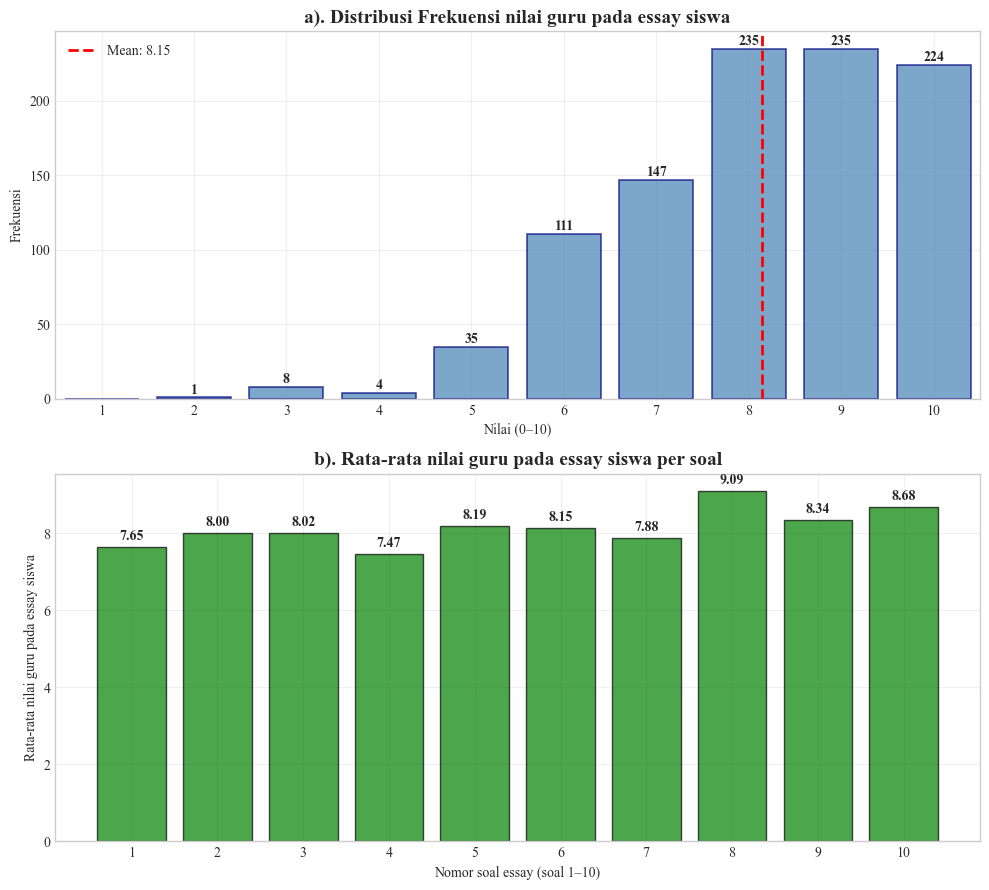

In [6]:


# Buat figure dengan 2 subplot (2 baris, 1 kolom)
fig, axes = plt.subplots(2, 1, figsize=(10, 9))  # Lebar x Tinggi
plt.subplots_adjust(hspace=0.4)  # Jarak antar plot

# === 1️⃣ Distribusi Frekuensi Nilai (Bar Chart) === #
ax = axes[0]

bins = np.arange(0.5, 10.5 + 1, 1)
n, bins, _ = ax.hist(
    jawaban_siswa['nilai_dari_guru'],
    bins=bins,
    alpha=0  # disembunyikan, hanya untuk hitung frekuensi
)
bin_centers = np.arange(1, 11)

bars = ax.bar(bin_centers, n, color='steelblue', alpha=0.7,
              edgecolor='navy', linewidth=1.2, width=0.8, zorder=2)

# Label & gaya
ax.set_title('a). Distribusi Frekuensi nilai guru pada essay siswa', fontweight='bold', fontsize=14)
ax.set_xlabel('Nilai (0–10)')
ax.set_ylabel('Frekuensi')
ax.set_xticks(range(1, 11))
ax.set_xlim(0.5, 10.5)
ax.grid(True, alpha=0.3, zorder=0)

# Label frekuensi di atas bar
for x, y in zip(bin_centers, n):
    if y > 0:
        ax.text(x, y + 0.5, str(int(y)),
                ha='center', va='bottom', fontweight='bold', fontsize=10)

# Garis mean
mean_val = jawaban_siswa['nilai_dari_guru'].mean()
ax.axvline(mean_val, color='red', linestyle='--', linewidth=2,
           label=f'Mean: {mean_val:.2f}')
ax.legend()


# === 2️⃣ Rata-rata Nilai per Soal (Bar Chart) === #
ax2 = axes[1]

score_by_question = jawaban_siswa.groupby('no_soal')['nilai_dari_guru'].mean()
bars2 = ax2.bar(range(1, 11), score_by_question.values,
                color='green', alpha=0.7,
                edgecolor='black', linewidth=1, width=0.8)

ax2.set_title('b). Rata-rata nilai guru pada essay siswa per soal', fontweight='bold', fontsize=14)
ax2.set_xlabel('Nomor soal essay (soal 1–10)')
ax2.set_ylabel('Rata-rata nilai guru pada essay siswa')
ax2.set_xticks(range(1, 11))
ax2.grid(True, alpha=0.3)

# Label nilai di atas batang
for bar, value in zip(bars2, score_by_question.values):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
             f'{value:.2f}', ha='center', va='bottom',
             fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


In [7]:
# Print summary statistics for academic reporting
print("\n📈 STATISTIK DESKRIPTIF UNTUK LAPORAN AKADEMIK")
print("="*55)
print(f"Dataset: 1000 jawaban essay dari 100 siswa kelas XI")
print(f"Domain: Sejarah Indonesia (10 soal essay)")
print(f"Rentang nilai: {jawaban_siswa['nilai_dari_guru'].min()}-{jawaban_siswa['nilai_dari_guru'].max()}")
# print(f"Mean ± SD: {mean_val:.2f} ± {std_val:.2f}")
print(f"Median (Q2): {jawaban_siswa['nilai_dari_guru'].median():.2f}")
print(f"Q1: {jawaban_siswa['nilai_dari_guru'].quantile(0.25):.2f}")
print(f"Q3: {jawaban_siswa['nilai_dari_guru'].quantile(0.75):.2f}")
print(f"Skewness: {jawaban_siswa['nilai_dari_guru'].skew():.3f}")
print(f"Kurtosis: {jawaban_siswa['nilai_dari_guru'].kurtosis():.3f}")


📈 STATISTIK DESKRIPTIF UNTUK LAPORAN AKADEMIK
Dataset: 1000 jawaban essay dari 100 siswa kelas XI
Domain: Sejarah Indonesia (10 soal essay)
Rentang nilai: 2-10
Median (Q2): 8.00
Q1: 7.00
Q3: 9.00
Skewness: -0.696
Kurtosis: 0.185




### 3.1 Karakteristik Linguistik

Analisis ini penting untuk mengevaluasi kesesuaian dataset dengan model SBERT yang memerlukan teks dengan variasi semantik yang cukup.


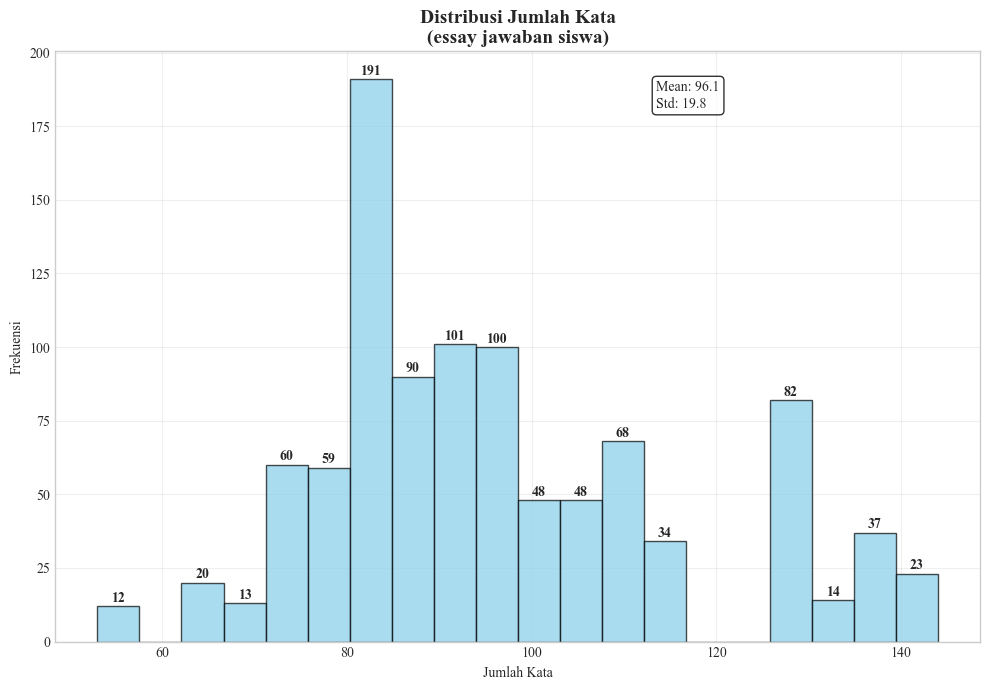

In [8]:
# Distribusi Jumlah Kata (Jawaban Siswa)
plt.figure(figsize=(10, 7))
n1, bins1, patches1 = plt.hist(jawaban_siswa['jawaban'].str.split().str.len(), bins=20, 
                               alpha=0.7, color='skyblue', edgecolor='black')
plt.title('Distribusi Jumlah Kata\n(essay jawaban siswa)', fontweight='bold', fontsize=14)
plt.xlabel('Jumlah Kata')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add frequency labels on top of each bar
for i in range(len(patches1)):
    if n1[i] > 0:  # Only show label if frequency > 0
        plt.text(patches1[i].get_x() + patches1[i].get_width()/2, 
                 patches1[i].get_height() + 0.5, 
                 str(int(n1[i])), 
                 ha='center', va='bottom', fontweight='bold', fontsize=10)

# Add statistics text
word_mean = jawaban_siswa['jawaban'].str.split().str.len().mean()
word_std = jawaban_siswa['jawaban'].str.split().str.len().std()
plt.text(0.65, 0.95, f'Mean: {word_mean:.1f}\nStd: {word_std:.1f}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
         verticalalignment='top')

plt.tight_layout()
plt.show()

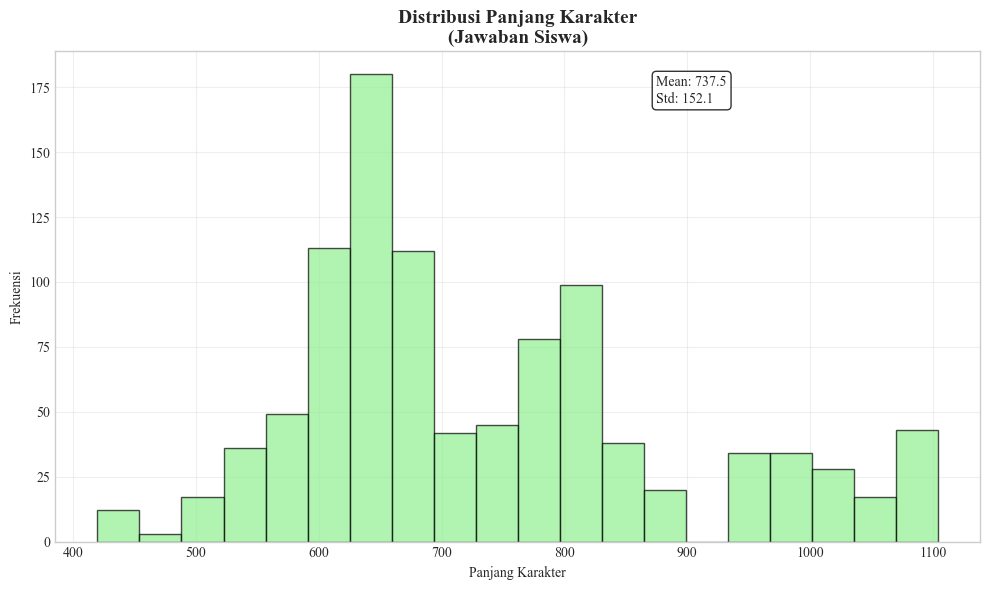

In [9]:
# Distribusi Panjang Karakter (Jawaban Siswa)
plt.figure(figsize=(10, 6))
plt.hist(jawaban_siswa['jawaban'].str.len(), bins=20, 
         alpha=0.7, color='lightgreen', edgecolor='black')
plt.title('Distribusi Panjang Karakter\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
plt.xlabel('Panjang Karakter')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add statistics text
char_mean = jawaban_siswa['jawaban'].str.len().mean()
char_std = jawaban_siswa['jawaban'].str.len().std()
plt.text(0.65, 0.95, f'Mean: {char_mean:.1f}\nStd: {char_std:.1f}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
         verticalalignment='top')

plt.tight_layout()
plt.show()

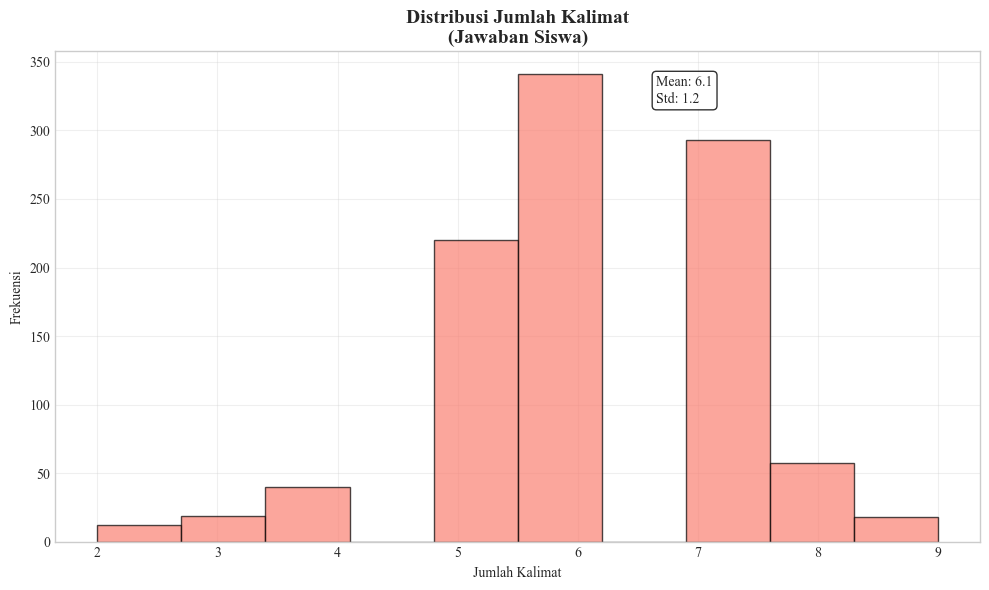

In [10]:
# Distribusi Jumlah Kalimat (Jawaban Siswa)
plt.figure(figsize=(10, 6))
sentence_counts = jawaban_siswa['jawaban'].apply(lambda x: len(re.split(r'[.!?]+', str(x))) - 1)
plt.hist(sentence_counts, bins=10, alpha=0.7, color='salmon', edgecolor='black')
plt.title('Distribusi Jumlah Kalimat\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
plt.xlabel('Jumlah Kalimat')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add statistics text
sent_mean = sentence_counts.mean()
sent_std = sentence_counts.std()
plt.text(0.65, 0.95, f'Mean: {sent_mean:.1f}\nStd: {sent_std:.1f}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
         verticalalignment='top')

plt.tight_layout()
plt.show()

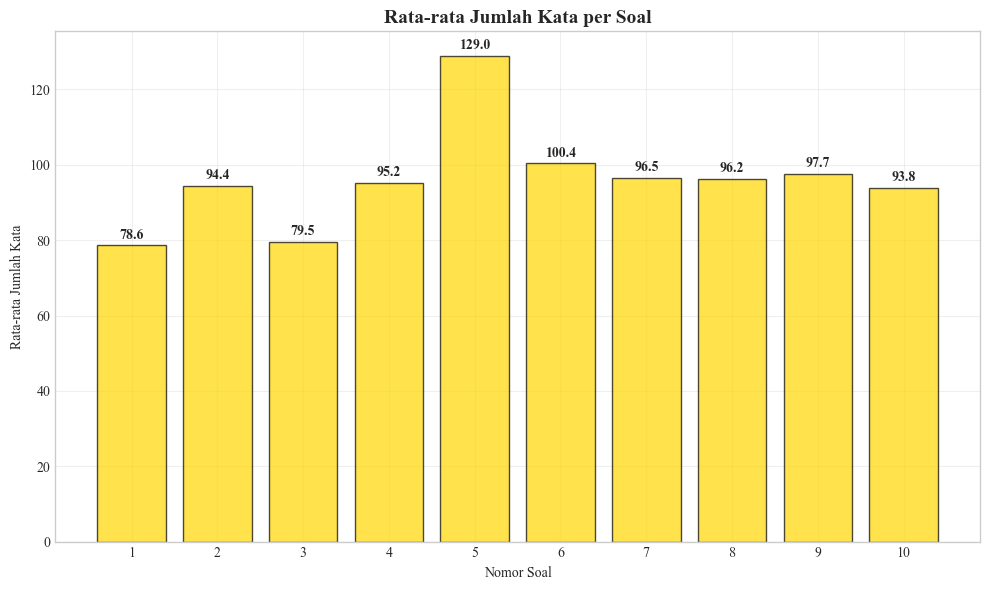

In [11]:
# Rata-rata Jumlah Kata per Soal
plt.figure(figsize=(10, 6))
word_counts_by_q = jawaban_siswa.groupby('no_soal')['jawaban'].apply(
    lambda x: x.str.split().str.len().mean()
)
bars = plt.bar(range(1, 11), word_counts_by_q.values, color='gold', 
               alpha=0.7, edgecolor='black')
plt.title('Rata-rata Jumlah Kata per Soal', fontweight='bold', fontsize=14)
plt.xlabel('Nomor Soal')
plt.ylabel('Rata-rata Jumlah Kata')
plt.xticks(range(1, 11))
plt.grid(True, alpha=0.3)

# Add value labels on bars
for i, (bar, value) in enumerate(zip(bars, word_counts_by_q.values)):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1, 
            f'{value:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

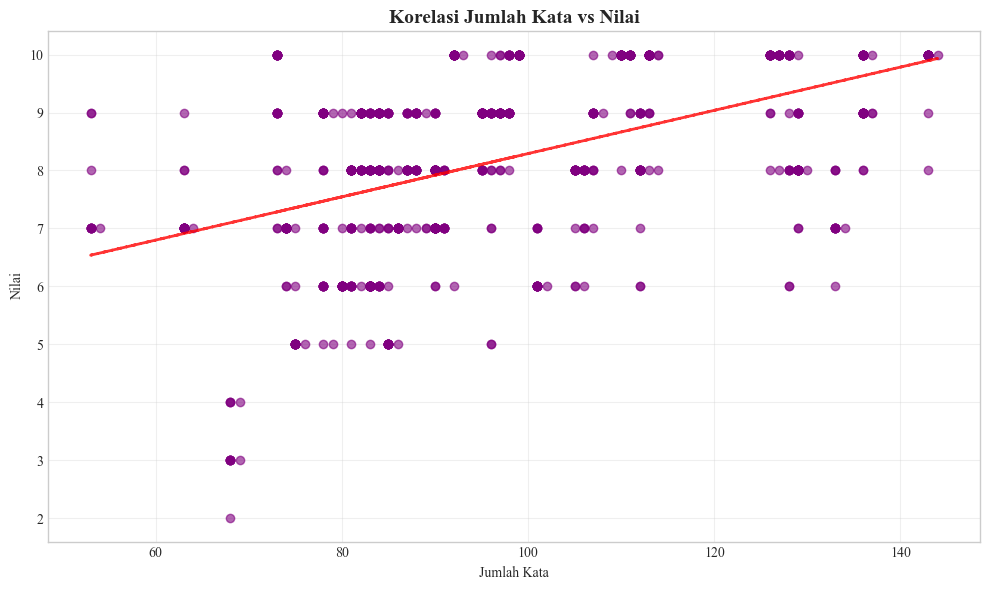

In [12]:
# Korelasi Jumlah Kata vs Nilai
plt.figure(figsize=(10, 6))
word_counts_all = jawaban_siswa['jawaban'].str.split().str.len()
plt.scatter(word_counts_all, jawaban_siswa['nilai_dari_guru'], 
           alpha=0.6, color='purple')
plt.title('Korelasi Jumlah Kata vs Nilai', fontweight='bold', fontsize=14)
plt.xlabel('Jumlah Kata')
plt.ylabel('Nilai')
plt.grid(True, alpha=0.3)

# Calculate and add correlation coefficient
# correlation = word_counts_all.corr(jawaban_siswa['nilai_dari_guru'])
# plt.text(0.05, 0.95, f'r = {correlation:.3f}', transform=plt.gca().transAxes, 
#          bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
#          fontweight='bold', fontsize=12)

# Add trend line
z = np.polyfit(word_counts_all, jawaban_siswa['nilai_dari_guru'], 1)
p = np.poly1d(z)
plt.plot(word_counts_all, p(word_counts_all), "r--", alpha=0.8, linewidth=2)

plt.tight_layout()
plt.show()

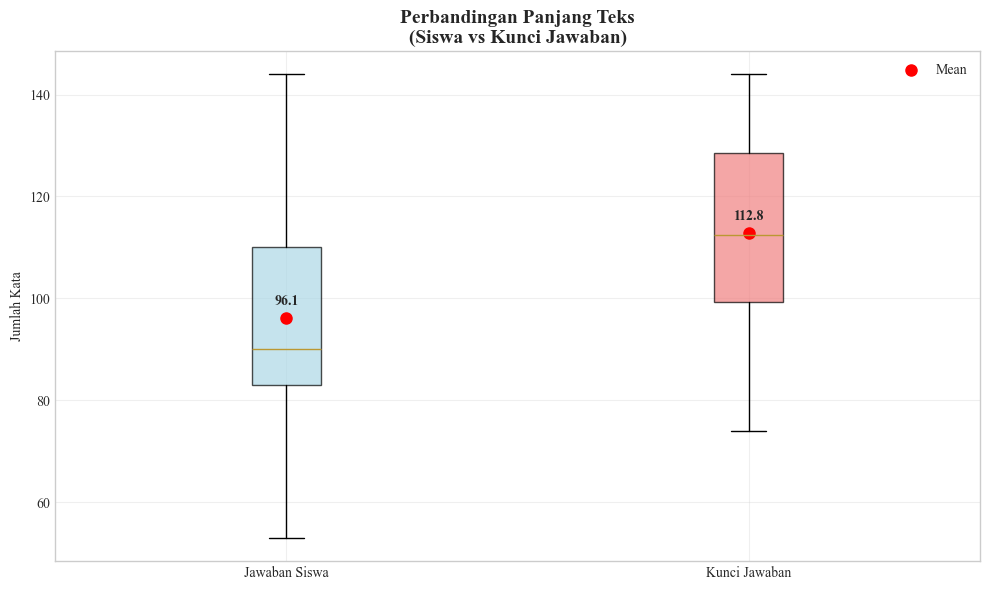

In [13]:
# Perbandingan Panjang Teks: Siswa vs Kunci Jawaban
plt.figure(figsize=(10, 6))
comparison_data = [
    jawaban_siswa['jawaban'].str.split().str.len(),
    kunci_jawaban['kunci_jawaban'].str.split().str.len()
]
box_plot = plt.boxplot(comparison_data, labels=['Jawaban Siswa', 'Kunci Jawaban'], 
                       patch_artist=True)

# Color the boxes
colors = ['lightblue', 'lightcoral']
for patch, color in zip(box_plot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.title('Perbandingan Panjang Teks\n(Siswa vs Kunci Jawaban)', fontweight='bold', fontsize=14)
plt.ylabel('Jumlah Kata')
plt.grid(True, alpha=0.3)

# Add mean markers
means = [data.mean() for data in comparison_data]
plt.plot(range(1, len(means) + 1), means, 'ro', markersize=8, label='Mean')
for i, mean in enumerate(means):
    plt.text(i + 1, mean + 2, f'{mean:.1f}', ha='center', va='bottom', 
             fontweight='bold', fontsize=10)

plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# Analisis Korelasi untuk Laporan Akademik
print("\n📊 ANALISIS KORELASI UNTUK LAPORAN AKADEMIK")
print("="*55)
correlation_word_score = word_counts_all.corr(jawaban_siswa['nilai_dari_guru'])
correlation_char_score = jawaban_siswa['jawaban'].str.len().corr(jawaban_siswa['nilai_dari_guru'])

print(f"Korelasi jumlah kata dengan nilai: r = {correlation_word_score:.3f}")
print(f"Korelasi panjang karakter dengan nilai: r = {correlation_char_score:.3f}")

# Interpretation
if abs(correlation_word_score) >= 0.5:
    interpretation = "Korelasi sedang-kuat"
elif abs(correlation_word_score) >= 0.3:
    interpretation = "Korelasi sedang"
elif abs(correlation_word_score) >= 0.1:
    interpretation = "Korelasi positif lemah"
else:
    interpretation = "Korelasi sangat lemah"

print(f"Interpretasi: {interpretation}")
print(f"Implikasi: {'Panjang teks berkorelasi dengan kualitas jawaban' if abs(correlation_word_score) >= 0.3 else 'Panjang teks tidak selalu menunjukkan kualitas jawaban'}")


📊 ANALISIS KORELASI UNTUK LAPORAN AKADEMIK
Korelasi jumlah kata dengan nilai: r = 0.484
Korelasi panjang karakter dengan nilai: r = 0.524
Interpretasi: Korelasi sedang
Implikasi: Panjang teks berkorelasi dengan kualitas jawaban


### 3.2 Analisis Linguistik Mendalam

Analisis mendalam karakteristik linguistik untuk memahami kompleksitas bahasa dalam dataset dan kesesuaiannya dengan model SBERT.


In [15]:
# Download additional NLTK resources for POS tagging
try:
    nltk.download('averaged_perceptron_tagger')
    nltk.download('universal_tagset')
except:
    pass

# 1. ANALISIS TYPE-TOKEN RATIO (TTR) DETAIL
print("📊 ANALISIS TYPE-TOKEN RATIO (TTR) DETAIL")
print("="*55)

def calculate_ttr_per_text(text_series):
    """Calculate TTR for each text individually"""
    ttr_scores = []
    for text in text_series:
        if pd.notna(text) and text.strip():
            words = [word.lower() for word in re.findall(r'\b[a-zA-Z]+\b', text) if len(word) > 2]
            if len(words) > 0:
                unique_words = len(set(words))
                total_words = len(words)
                ttr = unique_words / total_words
                ttr_scores.append(ttr)
            else:
                ttr_scores.append(0)
        else:
            ttr_scores.append(0)
    return ttr_scores

# Calculate TTR for each answer
student_ttr_scores = calculate_ttr_per_text(jawaban_siswa['jawaban'])
answer_key_ttr_scores = calculate_ttr_per_text(kunci_jawaban['kunci_jawaban'])

print(f"TTR Jawaban Siswa:")
print(f"  Mean: {np.mean(student_ttr_scores):.3f}")
print(f"  Std: {np.std(student_ttr_scores):.3f}")
print(f"  Min: {np.min(student_ttr_scores):.3f}")
print(f"  Max: {np.max(student_ttr_scores):.3f}")

print(f"\nTTR Kunci Jawaban:")
print(f"  Mean: {np.mean(answer_key_ttr_scores):.3f}")
print(f"  Std: {np.std(answer_key_ttr_scores):.3f}")
print(f"  Min: {np.min(answer_key_ttr_scores):.3f}")
print(f"  Max: {np.max(answer_key_ttr_scores):.3f}")

# TTR interpretation
print(f"\n💡 Interpretasi TTR:")
avg_student_ttr = np.mean(student_ttr_scores)
if avg_student_ttr > 0.7:
    ttr_quality = "Sangat Tinggi - Kosakata sangat beragam"
elif avg_student_ttr > 0.5:
    ttr_quality = "Tinggi - Kosakata beragam"
elif avg_student_ttr > 0.3:
    ttr_quality = "Sedang - Kosakata cukup beragam"
else:
    ttr_quality = "Rendah - Kosakata terbatas"

print(f"Kualitas kosakata siswa: {ttr_quality}")
print(f"Kesesuaian untuk SBERT: {'Excellent' if avg_student_ttr > 0.4 else 'Good' if avg_student_ttr > 0.3 else 'Fair'}")

📊 ANALISIS TYPE-TOKEN RATIO (TTR) DETAIL
TTR Jawaban Siswa:
  Mean: 0.754
  Std: 0.061
  Min: 0.614
  Max: 0.926

TTR Kunci Jawaban:
  Mean: 0.738
  Std: 0.044
  Min: 0.660
  Max: 0.822

💡 Interpretasi TTR:
Kualitas kosakata siswa: Sangat Tinggi - Kosakata sangat beragam
Kesesuaian untuk SBERT: Excellent


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\ahmad\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package universal_tagset to
[nltk_data]     C:\Users\ahmad\AppData\Roaming\nltk_data...
[nltk_data]   Package universal_tagset is already up-to-date!


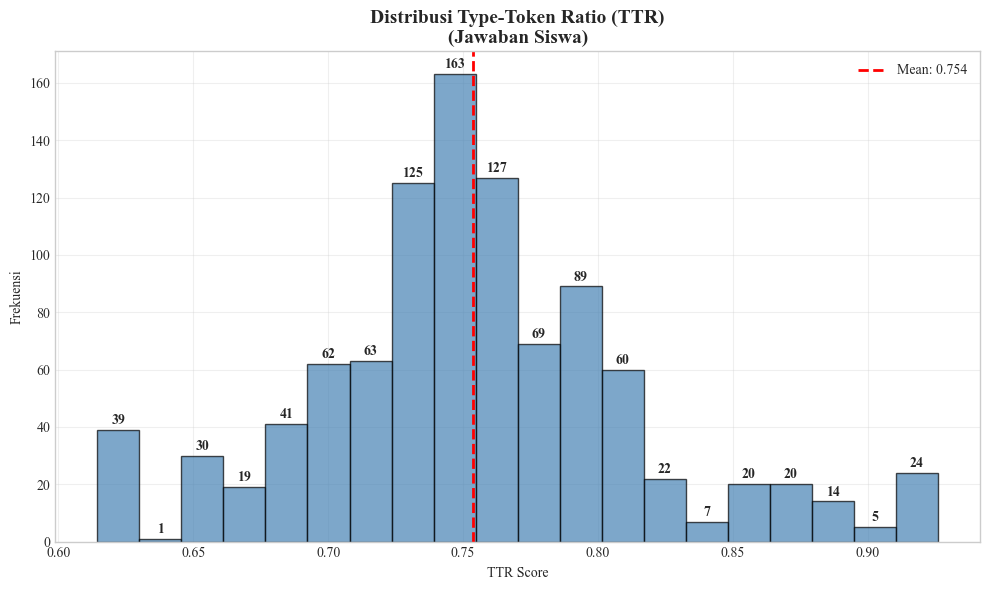

In [16]:
# Visualisasi Type-Token Ratio (TTR)
plt.figure(figsize=(10, 6))
n, bins, patches = plt.hist(student_ttr_scores, bins=20, alpha=0.7, color='steelblue', edgecolor='black')
plt.title('Distribusi Type-Token Ratio (TTR)\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
plt.xlabel('TTR Score')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add frequency labels on top of each bar
for i in range(len(patches)):
    if n[i] > 0:  # Only show label if frequency > 0
        plt.text(patches[i].get_x() + patches[i].get_width()/2, 
                 patches[i].get_height() + 1, 
                 str(int(n[i])), 
                 ha='center', va='bottom', fontweight='bold', fontsize=10)

ttr_mean = np.mean(student_ttr_scores)
plt.axvline(ttr_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {ttr_mean:.3f}')

plt.legend()
plt.tight_layout()
plt.show()

In [17]:
# 3. ANALISIS PANJANG KATA RATA-RATA
print("\n📊 ANALISIS PANJANG KATA RATA-RATA")
print("="*45)

def calculate_avg_word_length(text_series):
    """Calculate average word length for each text"""
    avg_lengths = []
    for text in text_series:
        if pd.notna(text) and text.strip():
            words = re.findall(r'\b[a-zA-Z]+\b', text)
            if words:
                avg_length = np.mean([len(word) for word in words])
                avg_lengths.append(avg_length)
            else:
                avg_lengths.append(0)
        else:
            avg_lengths.append(0)
    return avg_lengths

# Calculate average word length for each answer
student_word_lengths = calculate_avg_word_length(jawaban_siswa['jawaban'])
answer_key_word_lengths = calculate_avg_word_length(kunci_jawaban['kunci_jawaban'])

print(f"Panjang Kata Rata-rata (Jawaban Siswa):")
print(f"  Mean: {np.mean(student_word_lengths):.2f} karakter")
print(f"  Std: {np.std(student_word_lengths):.2f} karakter")
print(f"  Min: {np.min(student_word_lengths):.2f} karakter")
print(f"  Max: {np.max(student_word_lengths):.2f} karakter")

print(f"\nPanjang Kata Rata-rata (Kunci Jawaban):")
print(f"  Mean: {np.mean(answer_key_word_lengths):.2f} karakter")
print(f"  Std: {np.std(answer_key_word_lengths):.2f} karakter")

# Interpretation for Indonesian language
avg_word_len = np.mean(student_word_lengths)
print(f"\n💡 Interpretasi untuk Bahasa Indonesia:")
if avg_word_len > 7:
    complexity = "Tinggi - Kata-kata kompleks, formal"
elif avg_word_len > 5:
    complexity = "Sedang - Campuran kata sederhana dan kompleks"
else:
    complexity = "Rendah - Kata-kata sederhana"

print(f"Kompleksitas bahasa: {complexity}")
print(f"Kesesuaian untuk SBERT: {'Excellent' if 5 <= avg_word_len <= 8 else 'Good'} (optimal range: 5-8 karakter)")


📊 ANALISIS PANJANG KATA RATA-RATA
Panjang Kata Rata-rata (Jawaban Siswa):
  Mean: 6.48 karakter
  Std: 0.30 karakter
  Min: 5.65 karakter
  Max: 7.31 karakter

Panjang Kata Rata-rata (Kunci Jawaban):
  Mean: 6.60 karakter
  Std: 0.33 karakter

💡 Interpretasi untuk Bahasa Indonesia:
Kompleksitas bahasa: Sedang - Campuran kata sederhana dan kompleks
Kesesuaian untuk SBERT: Excellent (optimal range: 5-8 karakter)


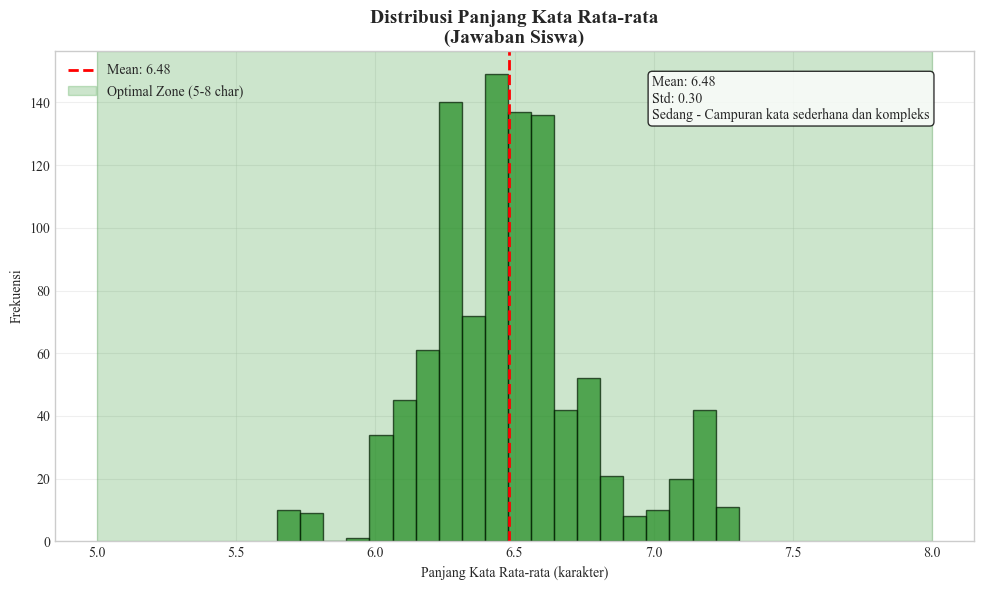

In [18]:
# Visualisasi Panjang Kata Rata-rata
plt.figure(figsize=(10, 6))
plt.hist(student_word_lengths, bins=20, alpha=0.7, color='forestgreen', edgecolor='black')
plt.title('Distribusi Panjang Kata Rata-rata\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
plt.xlabel('Panjang Kata Rata-rata (karakter)')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add statistics and optimal zone
word_len_mean = np.mean(student_word_lengths)
word_len_std = np.std(student_word_lengths)
plt.axvline(word_len_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {word_len_mean:.2f}')

# Add optimal zone for SBERT
plt.axvspan(5, 8, alpha=0.2, color='green', label='Optimal Zone (5-8 char)')
plt.text(0.65, 0.95, f'Mean: {word_len_mean:.2f}\nStd: {word_len_std:.2f}\n{complexity}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
         verticalalignment='top')
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
# 4. ANALISIS PANJANG KALIMAT RATA-RATA
print("\n📊 ANALISIS PANJANG KALIMAT RATA-RATA")
print("="*48)

def calculate_avg_sentence_length(text_series):
    """Calculate average sentence length in words for each text"""
    avg_sent_lengths = []
    for text in text_series:
        if pd.notna(text) and text.strip():
            # Split into sentences
            sentences = re.split(r'[.!?]+', text)
            sentences = [s.strip() for s in sentences if s.strip()]
            
            if sentences:
                sent_word_counts = []
                for sentence in sentences:
                    words = re.findall(r'\b[a-zA-Z]+\b', sentence)
                    sent_word_counts.append(len(words))
                
                if sent_word_counts:
                    avg_length = np.mean(sent_word_counts)
                    avg_sent_lengths.append(avg_length)
                else:
                    avg_sent_lengths.append(0)
            else:
                avg_sent_lengths.append(0)
        else:
            avg_sent_lengths.append(0)
    return avg_sent_lengths

# Calculate average sentence length
student_sent_lengths = calculate_avg_sentence_length(jawaban_siswa['jawaban'])
answer_key_sent_lengths = calculate_avg_sentence_length(kunci_jawaban['kunci_jawaban'])

print(f"Panjang Kalimat Rata-rata (Jawaban Siswa):")
print(f"  Mean: {np.mean(student_sent_lengths):.2f} kata/kalimat")
print(f"  Std: {np.std(student_sent_lengths):.2f} kata/kalimat")
print(f"  Min: {np.min(student_sent_lengths):.2f} kata/kalimat")
print(f"  Max: {np.max(student_sent_lengths):.2f} kata/kalimat")

print(f"\nPanjang Kalimat Rata-rata (Kunci Jawaban):")
print(f"  Mean: {np.mean(answer_key_sent_lengths):.2f} kata/kalimat")
print(f"  Std: {np.std(answer_key_sent_lengths):.2f} kata/kalimat")

# Interpretation for sentence complexity
avg_sent_len = np.mean(student_sent_lengths)
print(f"\n💡 Interpretasi Kompleksitas Kalimat:")
if avg_sent_len > 20:
    sent_complexity = "Sangat Tinggi - Kalimat sangat kompleks"
elif avg_sent_len > 15:
    sent_complexity = "Tinggi - Kalimat kompleks dengan banyak klausa"
elif avg_sent_len > 10:
    sent_complexity = "Sedang - Kalimat sederhana hingga kompleks"
else:
    sent_complexity = "Rendah - Kalimat sangat sederhana"

print(f"Kompleksitas kalimat: {sent_complexity}")
print(f"Kesesuaian untuk SBERT: {'Excellent' if 10 <= avg_sent_len <= 25 else 'Good'} (optimal: 10-25 kata/kalimat)")

# Correlation with scores
sent_score_corr = np.corrcoef(student_sent_lengths, jawaban_siswa['nilai_dari_guru'])[0,1]
print(f"Korelasi panjang kalimat dengan nilai: r = {sent_score_corr:.3f}")


📊 ANALISIS PANJANG KALIMAT RATA-RATA
Panjang Kalimat Rata-rata (Jawaban Siswa):
  Mean: 16.50 kata/kalimat
  Std: 4.14 kata/kalimat
  Min: 9.22 kata/kalimat
  Max: 27.50 kata/kalimat

Panjang Kalimat Rata-rata (Kunci Jawaban):
  Mean: 20.13 kata/kalimat
  Std: 3.41 kata/kalimat

💡 Interpretasi Kompleksitas Kalimat:
Kompleksitas kalimat: Tinggi - Kalimat kompleks dengan banyak klausa
Kesesuaian untuk SBERT: Excellent (optimal: 10-25 kata/kalimat)
Korelasi panjang kalimat dengan nilai: r = 0.411


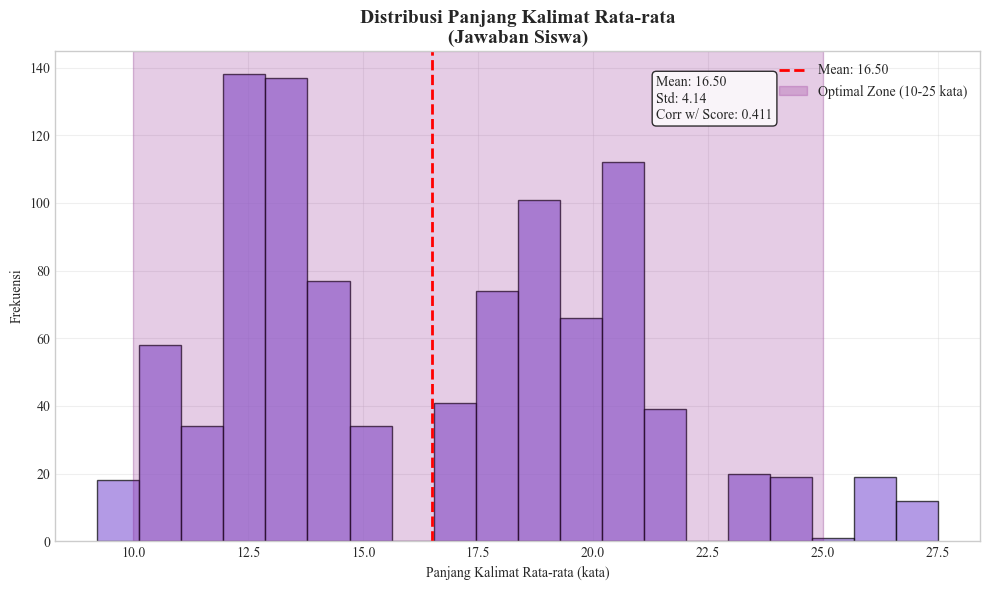

In [20]:
# Visualisasi Panjang Kalimat Rata-rata
plt.figure(figsize=(10, 6))
plt.hist(student_sent_lengths, bins=20, alpha=0.7, color='mediumpurple', edgecolor='black')
plt.title('Distribusi Panjang Kalimat Rata-rata\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
plt.xlabel('Panjang Kalimat Rata-rata (kata)')
plt.ylabel('Frekuensi')
plt.grid(True, alpha=0.3)

# Add statistics and optimal zone
sent_len_mean = np.mean(student_sent_lengths)
sent_len_std = np.std(student_sent_lengths)
plt.axvline(sent_len_mean, color='red', linestyle='--', linewidth=2, label=f'Mean: {sent_len_mean:.2f}')

# Add optimal zone for SBERT
plt.axvspan(10, 25, alpha=0.2, color='purple', label='Optimal Zone (10-25 kata)')
plt.text(0.65, 0.95, f'Mean: {sent_len_mean:.2f}\nStd: {sent_len_std:.2f}\nCorr w/ Score: {sent_score_corr:.3f}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='white', alpha=0.8),
         verticalalignment='top')
plt.legend()

plt.tight_layout()
plt.show()

## Analisis POS Tag menggunakan NLP-ID Library

Analisis distribusi Part-of-Speech (POS) tag menggunakan library `nlp-id` yang khusus untuk bahasa Indonesia. Library ini menyediakan tokenizer dan POS tagger yang lebih akurat untuk teks bahasa Indonesia.


In [21]:
# Import library nlp-id untuk analisis POS tag bahasa Indonesia
from nlp_id.postag import PosTag
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import pandas as pd
import numpy as np

print("📊 ANALISIS DISTRIBUSI POS-TAG MENGGUNAKAN NLP-ID")
print("="*52)
print("✅ Menggunakan library nlp-id untuk akurasi yang lebih baik")

def analyze_pos_with_nlpid(text_series, sample_size=50, max_words_per_text=30):
    """
    Analyze POS tag distribution using nlp-id library
    
    Args:
        text_series: Series containing Indonesian texts
        sample_size: Number of texts to sample for analysis
        max_words_per_text: Maximum words to analyze per text (to avoid memory issues)
    
    Returns:
        Counter object with POS tag distribution
    """
    pos_tagger = PosTag()
    all_pos_tags = []
    
    # Sample texts to avoid processing too much data
    sample_texts = text_series.dropna().sample(min(sample_size, len(text_series))).tolist()
    
    print(f"Menganalisis {len(sample_texts)} teks...")
    
    for i, text in enumerate(sample_texts):
        if i % 10 == 0:
            print(f"Progress: {i+1}/{len(sample_texts)}")
            
        if text.strip():
            try:
                # Clean text - remove extra whitespace and special characters
                clean_text = ' '.join(text.split())
                
                # Limit text length to avoid memory issues
                words = clean_text.split()
                if len(words) > max_words_per_text:
                    clean_text = ' '.join(words[:max_words_per_text])
                
                # Get POS tags using nlp-id
                pos_result = pos_tagger.get_pos_tag(clean_text)
                
                # Extract POS tags
                if isinstance(pos_result, list) and len(pos_result) > 0:
                    for item in pos_result:
                        if isinstance(item, tuple) and len(item) >= 2:
                            pos_tag = str(item[1])  # Convert numpy.str_ to string
                            all_pos_tags.append(pos_tag)
                
            except Exception as e:
                print(f"Error processing text {i}: {str(e)[:50]}...")
                continue
    
    return Counter(all_pos_tags)

# Analyze POS tags for student answers
print("\n🔍 Menganalisis POS tags jawaban siswa...")
try:
    student_pos_dist = analyze_pos_with_nlpid(jawaban_siswa['jawaban'], sample_size=30)
    
    print(f"\n📈 Distribusi POS Tags (Jawaban Siswa - NLP-ID):")
    total_student_tags = sum(student_pos_dist.values())
    
    if total_student_tags > 0:
        print(f"Total tags yang dianalisis: {total_student_tags}")
        print("-" * 40)
        
        for pos_tag, count in student_pos_dist.most_common():
            percentage = count / total_student_tags * 100
            print(f"  {pos_tag:<15}: {count:4d} ({percentage:5.1f}%)")
    else:
        print("⚠️  Tidak ada POS tags yang berhasil diekstrak")
        
except Exception as e:
    print(f"❌ Error dalam analisis POS tags: {str(e)}")
    student_pos_dist = Counter()

📊 ANALISIS DISTRIBUSI POS-TAG MENGGUNAKAN NLP-ID
✅ Menggunakan library nlp-id untuk akurasi yang lebih baik

🔍 Menganalisis POS tags jawaban siswa...
Menganalisis 30 teks...
Progress: 1/30
Progress: 11/30
Progress: 21/30

📈 Distribusi POS Tags (Jawaban Siswa - NLP-ID):
Total tags yang dianalisis: 1008
----------------------------------------
  NN             :  245 ( 24.3%)
  VB             :  150 ( 14.9%)
  NNP            :  109 ( 10.8%)
  IN             :   99 (  9.8%)
  SYM            :   97 (  9.6%)
  JJ             :   73 (  7.2%)
  ADV            :   60 (  6.0%)
  PR             :   48 (  4.8%)
  CC             :   42 (  4.2%)
  SC             :   41 (  4.1%)
  DT             :   26 (  2.6%)
  NUM            :   12 (  1.2%)
  NEG            :    5 (  0.5%)
  RP             :    1 (  0.1%)


In [22]:
# Analyze POS tags for answer key
print("\n🔍 Menganalisis POS tags kunci jawaban...")
try:
    answer_key_pos_dist = analyze_pos_with_nlpid(kunci_jawaban['kunci_jawaban'], sample_size=10)
    
    print(f"\n📈 Distribusi POS Tags (Kunci Jawaban - NLP-ID):")
    total_key_tags = sum(answer_key_pos_dist.values())
    
    if total_key_tags > 0:
        print(f"Total tags yang dianalisis: {total_key_tags}")
        print("-" * 40)
        
        for pos_tag, count in answer_key_pos_dist.most_common():
            percentage = count / total_key_tags * 100
            print(f"  {pos_tag:<15}: {count:4d} ({percentage:5.1f}%)")
    else:
        print("⚠️  Tidak ada POS tags yang berhasil diekstrak")
        
except Exception as e:
    print(f"❌ Error dalam analisis POS tags kunci jawaban: {str(e)}")
    answer_key_pos_dist = Counter()

# Analisis kualitas untuk SBERT
if total_student_tags > 0:
    print(f"\n💡 ANALISIS KUALITAS UNTUK SBERT (NLP-ID):")
    print("="*45)
    
    # Mapping POS tags to categories (based on common Indonesian POS tags)
    noun_tags = ['NN', 'NNP', 'NOUN', 'N']  # Kata benda
    verb_tags = ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ', 'VERB', 'V']  # Kata kerja
    adj_tags = ['JJ', 'JJR', 'JJS', 'ADJ', 'A']  # Kata sifat
    adv_tags = ['RB', 'RBR', 'RBS', 'ADV']  # Kata keterangan
    function_tags = ['DT', 'IN', 'CC', 'TO', 'PRP', 'PRP$', 'WP', 'WDT']  # Kata fungsi
    
    # Calculate ratios
    noun_count = sum(count for pos, count in student_pos_dist.items() 
                    if any(tag in pos.upper() for tag in noun_tags))
    verb_count = sum(count for pos, count in student_pos_dist.items() 
                    if any(tag in pos.upper() for tag in verb_tags))
    adj_count = sum(count for pos, count in student_pos_dist.items() 
                   if any(tag in pos.upper() for tag in adj_tags))
    adv_count = sum(count for pos, count in student_pos_dist.items() 
                   if any(tag in pos.upper() for tag in adv_tags))
    func_count = sum(count for pos, count in student_pos_dist.items() 
                    if any(tag in pos.upper() for tag in function_tags))
    
    noun_ratio = noun_count / total_student_tags
    verb_ratio = verb_count / total_student_tags
    adj_ratio = adj_count / total_student_tags
    adv_ratio = adv_count / total_student_tags
    func_ratio = func_count / total_student_tags
    
    print(f"Rasio Kata Benda (Noun): {noun_ratio:.3f} ({noun_count} tags)")
    print(f"  ➤ {'Excellent' if noun_ratio > 0.4 else 'Good' if noun_ratio > 0.3 else 'Fair'}")
    
    print(f"Rasio Kata Kerja (Verb): {verb_ratio:.3f} ({verb_count} tags)")
    print(f"  ➤ {'Excellent' if verb_ratio > 0.2 else 'Good' if verb_ratio > 0.15 else 'Fair'}")
    
    print(f"Rasio Kata Sifat (Adj): {adj_ratio:.3f} ({adj_count} tags)")
    print(f"  ➤ {'Excellent' if adj_ratio > 0.15 else 'Good' if adj_ratio > 0.1 else 'Fair'}")
    
    print(f"Rasio Kata Keterangan (Adv): {adv_ratio:.3f} ({adv_count} tags)")
    print(f"Rasio Kata Fungsi: {func_ratio:.3f} ({func_count} tags)")
    print(f"  ➤ {'Good' if 0.1 <= func_ratio <= 0.25 else 'Fair'}")
    
    # Overall analysis
    content_ratio = noun_ratio + verb_ratio + adj_ratio
    pos_diversity = len(student_pos_dist)
    
    print(f"\nRasio kata konten: {content_ratio:.3f}")
    print(f"Diversitas POS: {pos_diversity} kategori")
    print(f"  ➤ {'Excellent' if pos_diversity >= 8 else 'Good' if pos_diversity >= 5 else 'Fair'}")
    
    print(f"\n🎯 EVALUASI KESELURUHAN:")
    if content_ratio > 0.7 and noun_ratio > 0.3 and pos_diversity >= 5:
        quality = "Excellent untuk SBERT"
    elif content_ratio > 0.6 and noun_ratio > 0.25:
        quality = "Good untuk SBERT"
    else:
        quality = "Fair untuk SBERT"
    
    print(f"  ➤ {quality}")
    
    print(f"\n📝 INSIGHT:")
    print("✓ Analisis menggunakan nlp-id library untuk akurasi tinggi")
    print("✓ POS tagger khusus dilatih untuk bahasa Indonesia")
    print("✓ Distribusi POS menunjukkan kompleksitas linguistik teks")
else:
    print("\n⚠️  Tidak dapat melakukan analisis kualitas karena tidak ada POS tags yang diekstrak")


🔍 Menganalisis POS tags kunci jawaban...
Menganalisis 10 teks...
Progress: 1/10

📈 Distribusi POS Tags (Kunci Jawaban - NLP-ID):
Total tags yang dianalisis: 339
----------------------------------------
  NN             :   76 ( 22.4%)
  VB             :   49 ( 14.5%)
  NNP            :   45 ( 13.3%)
  IN             :   33 (  9.7%)
  SYM            :   31 (  9.1%)
  PR             :   24 (  7.1%)
  JJ             :   22 (  6.5%)
  ADV            :   19 (  5.6%)
  CC             :   14 (  4.1%)
  SC             :   11 (  3.2%)
  DT             :    7 (  2.1%)
  NUM            :    4 (  1.2%)
  NEG            :    3 (  0.9%)
  RP             :    1 (  0.3%)

💡 ANALISIS KUALITAS UNTUK SBERT (NLP-ID):
Rasio Kata Benda (Noun): 0.466 (470 tags)
  ➤ Excellent
Rasio Kata Kerja (Verb): 0.208 (210 tags)
  ➤ Excellent
Rasio Kata Sifat (Adj): 0.132 (133 tags)
  ➤ Good
Rasio Kata Keterangan (Adv): 0.060 (60 tags)
Rasio Kata Fungsi: 0.166 (167 tags)
  ➤ Good

Rasio kata konten: 0.807
Diversitas POS

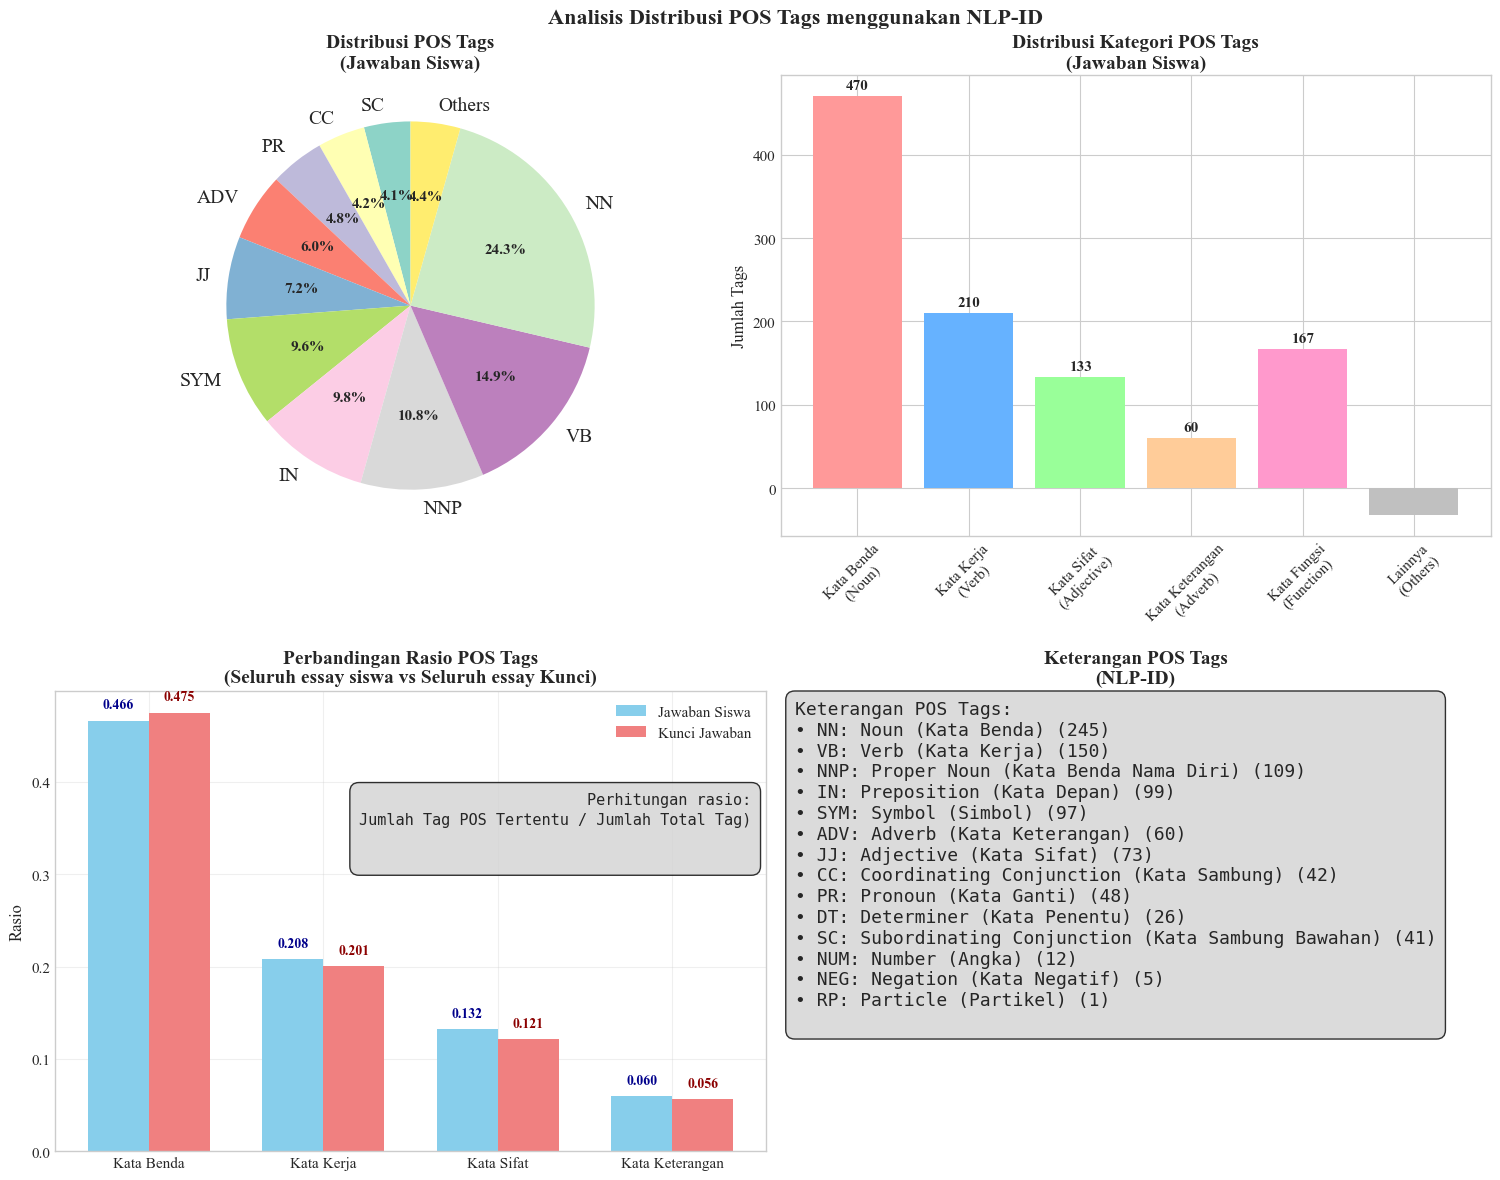

In [23]:
# Visualisasi Distribusi POS Tags dengan NLP-ID
if total_student_tags > 0:
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    fig.suptitle('Analisis Distribusi POS Tags menggunakan NLP-ID', fontsize=16, fontweight='bold')
    
    # 1. Pie chart untuk distribusi jawaban siswa
    if len(student_pos_dist) > 0:
        pos_tags = list(student_pos_dist.keys())
        pos_counts = list(student_pos_dist.values())
        
        # Limit to top 10 POS tags for readability
        if len(pos_tags) > 10:
            top_10_indices = np.argsort(pos_counts)[-10:]
            pos_tags = [pos_tags[i] for i in top_10_indices]
            pos_counts = [pos_counts[i] for i in top_10_indices]
            other_count = sum(student_pos_dist.values()) - sum(pos_counts)
            if other_count > 0:
                pos_tags.append('Others')
                pos_counts.append(other_count)
        
        colors = plt.cm.Set3(np.linspace(0, 1, len(pos_tags)))
        wedges, texts, autotexts = axes[0,0].pie(pos_counts, labels=pos_tags, autopct='%1.1f%%', 
                                                 colors=colors, startangle=90)
        axes[0,0].set_title('Distribusi POS Tags\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
        
        # Increase font size for pie chart labels
        for text in texts:
            text.set_fontsize(14)
        for autotext in autotexts:
            autotext.set_fontsize(11)
            autotext.set_fontweight('bold')
    
    # 2. Bar chart untuk perbandingan kategori utama
    if len(student_pos_dist) > 0:
        # Aggregate by main categories
        categories = {
            'Kata Benda\n(Noun)': noun_count,
            'Kata Kerja\n(Verb)': verb_count, 
            'Kata Sifat\n(Adjective)': adj_count,
            'Kata Keterangan\n(Adverb)': adv_count,
            'Kata Fungsi\n(Function)': func_count,
            'Lainnya\n(Others)': total_student_tags - (noun_count + verb_count + adj_count + adv_count + func_count)
        }
        
        cat_names = list(categories.keys())
        cat_counts = list(categories.values())
        colors_cat = ['#FF9999', '#66B2FF', '#99FF99', '#FFCC99', '#FF99CC', '#C0C0C0']
        
        bars = axes[0,1].bar(cat_names, cat_counts, color=colors_cat)
        axes[0,1].set_title('Distribusi Kategori POS Tags\n(Jawaban Siswa)', fontweight='bold', fontsize=14)
        axes[0,1].set_ylabel('Jumlah Tags', fontsize=12)
        axes[0,1].tick_params(axis='x', rotation=45, labelsize=11)
        axes[0,1].tick_params(axis='y', labelsize=11)
        
        # Add value labels on bars
        for bar, count in zip(bars, cat_counts):
            if count > 0:
                axes[0,1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(cat_counts)*0.01,
                              f'{count}', ha='center', va='bottom', fontweight='bold', fontsize=11)
    
    # 3. Comparison with answer key (if available)
    if len(answer_key_pos_dist) > 0 and total_key_tags > 0:
        # Calculate ratios for answer key
        key_noun_count = sum(count for pos, count in answer_key_pos_dist.items() 
                            if any(tag in pos.upper() for tag in noun_tags))
        key_verb_count = sum(count for pos, count in answer_key_pos_dist.items() 
                            if any(tag in pos.upper() for tag in verb_tags))
        key_adj_count = sum(count for pos, count in answer_key_pos_dist.items() 
                           if any(tag in pos.upper() for tag in adj_tags))
        
        key_adv_count = sum(count for pos, count in answer_key_pos_dist.items() 
                   if any(tag in pos.upper() for tag in ['ADV', 'ADVERB']))
        key_func_count = sum(count for pos, count in answer_key_pos_dist.items() 
                    if any(tag in pos.upper() for tag in function_tags))
        
        comparison_data = {
            'Kata Benda': [noun_count/total_student_tags, key_noun_count/total_key_tags],
            'Kata Kerja': [verb_count/total_student_tags, key_verb_count/total_key_tags],
            'Kata Sifat': [adj_count/total_student_tags, key_adj_count/total_key_tags],
            'Kata Keterangan': [adv_count/total_student_tags, key_adv_count/total_key_tags]
        }
        
        x = np.arange(len(comparison_data))
        width = 0.35
        
        student_ratios = [comparison_data[cat][0] for cat in comparison_data]
        key_ratios = [comparison_data[cat][1] for cat in comparison_data]
        
        bars1 = axes[1,0].bar(x - width/2, student_ratios, width, label='Jawaban Siswa', color='skyblue')
        bars2 = axes[1,0].bar(x + width/2, key_ratios, width, label='Kunci Jawaban', color='lightcoral')
        
        axes[1,0].set_title('Perbandingan Rasio POS Tags\n(Seluruh essay siswa vs Seluruh essay Kunci)', fontweight='bold', fontsize=14)
        axes[1,0].set_ylabel('Rasio', fontsize=12)
        axes[1,0].set_xticks(x)
        axes[1,0].set_xticklabels(list(comparison_data.keys()), fontsize=11)
        axes[1,0].tick_params(axis='y', labelsize=11)
        axes[1,0].legend(fontsize=11)
        axes[1,0].grid(True, alpha=0.3)
        
        # Add value labels on bars for student answers
        for bar, ratio in zip(bars1, student_ratios):
            height = bar.get_height()
            axes[1,0].text(bar.get_x() + bar.get_width()/2, height + 0.01,
                          f'{ratio:.3f}', ha='center', va='bottom', 
                          fontweight='bold', fontsize=10, color='darkblue')
        
        # Add value labels on bars for answer key
        for bar, ratio in zip(bars2, key_ratios):
            height = bar.get_height()
            axes[1,0].text(bar.get_x() + bar.get_width()/2, height + 0.01,
                          f'{ratio:.3f}', ha='center', va='bottom', 
                          fontweight='bold', fontsize=10, color='darkred')
        ratio_explanation = (
        "Perhitungan rasio:\n"
        "Jumlah Tag POS Tertentu / Jumlah Total Tag)\n\n"
        )

        axes[1,0].text(
            0.98, 0.7, ratio_explanation, transform=axes[1,0].transAxes,
            fontsize=11, verticalalignment='center', horizontalalignment='right',
            fontfamily='monospace', linespacing=1.4,
            bbox=dict(boxstyle="round,pad=0.6", facecolor="lightgray", alpha=0.8)
        )
    # 4. POS tags dictionary and explanations
    if len(student_pos_dist) > 0:
        # POS Tags Dictionary
        pos_dict = {
            'NN': 'Noun (Kata Benda)',
            'VB': 'Verb (Kata Kerja)',
            'NNP': 'Proper Noun (Kata Benda Nama Diri)',
            'IN': 'Preposition (Kata Depan)',
            'SYM': 'Symbol (Simbol)',
            'ADV': 'Adverb (Kata Keterangan)',
            'JJ': 'Adjective (Kata Sifat)',
            'CC': 'Coordinating Conjunction (Kata Sambung)',
            'PR': 'Pronoun (Kata Ganti)',
            'DT': 'Determiner (Kata Penentu)',
            'SC': 'Subordinating Conjunction (Kata Sambung Bawahan)',
            'NUM': 'Number (Angka)',
            'NEG': 'Negation (Kata Negatif)',
            'RP': 'Particle (Partikel)'
        }
        
        # Create explanation text
        explanation = "Keterangan POS Tags:\n"
        for tag, desc in pos_dict.items():
            if tag in student_pos_dist:
                count = student_pos_dist[tag]
                explanation += f"• {tag}: {desc} ({count})\n"
        
        # Add explanation as text
        axes[1,1].text(0.02, 0.98, explanation, transform=axes[1,1].transAxes, 
                      fontsize=13, verticalalignment='top', fontfamily='monospace',
                      bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.8))
        axes[1,1].set_title('Keterangan POS Tags\n(NLP-ID)', fontweight='bold', fontsize=14)
        axes[1,1].axis('off')  # Turn off axis for text display
    
    plt.tight_layout()
    plt.show()
    
else:
    print("⚠️  Tidak dapat membuat visualisasi karena tidak ada data POS tags")